Formato dos choques Z (trajetórias, dias): (10000, 252)
Formato da matriz de preços (trajetórias, dias): (10000, 252)


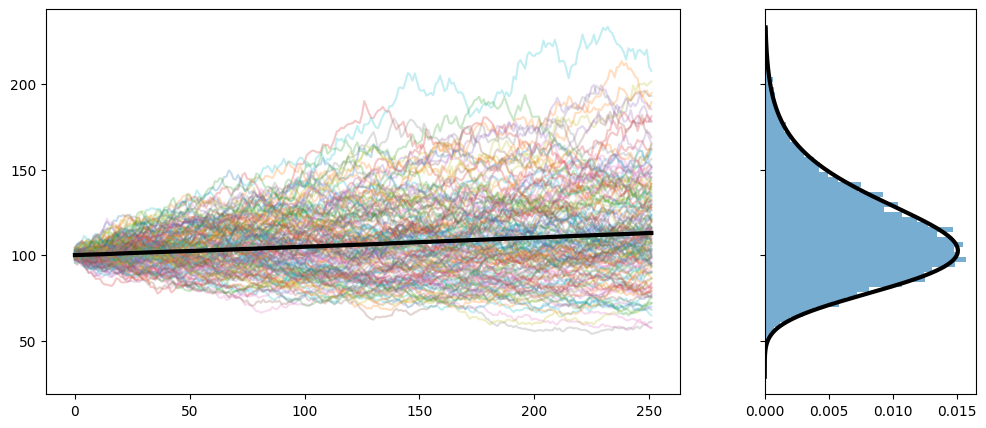

Preço final médio: 113.01
Preço final no percentil 5%: 72.54
Preço final no percentil 95%: 165.73
Probabilidade de terminar abaixo de S0 (%): 36.1
VaR 95% (perda em %): 27.5
CVaR 95% (perda média nos 5% piores, em %): 33.9
Preço da call por Monte Carlo: 12.54
Erro padrão do Monte Carlo: 0.19
Preço da call por Black-Scholes: 12.4
Percentil 5% do preço final com sigma = 40%: 54.03


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from math import log, sqrt, exp, erf

#Passo 1: parâmetros
S0 = 100.0        # preço inicial
mu = 0.12         # retorno esperado ao ano
sigma = 0.25      # volatilidade ao ano
T = 1.0           # horizonte em anos
passos = 252      # dias úteis
n_sim = 10_000    # trajetórias
dt = T / passos   # tamanho do passo

#Passo 2: choques aleatórios
rng = np.random.default_rng(42)
Z = rng.standard_normal((n_sim, passos))
print("Formato dos choques Z (trajetórias, dias):", Z.shape)

#Passo 3: retornos diários
drift = (mu - 0.5 * sigma**2) * dt
difusao = sigma * np.sqrt(dt) * Z
retornos = drift + difusao

#Passo 4: trajetórias
log_precos = np.cumsum(retornos, axis=1)
precos = S0 * np.exp(log_precos)
print("Formato da matriz de preços (trajetórias, dias):", precos.shape)
final = precos[:, -1]

#Passo 5: gráfico com a curva de sino
# curva teórica dos preços finais (log-normal)
m = np.log(S0) + (mu - 0.5 * sigma**2) * T
s = sigma * np.sqrt(T)
ys = np.linspace(final.min(), np.percentile(final, 99.9), 400)
expoente = -(np.log(ys) - m)**2 / (2 * s**2)
pdf = np.exp(expoente) / (ys * s * np.sqrt(2 * np.pi))

fig, (a, b) = plt.subplots(1, 2, sharey=True, figsize=(12, 5),
                           gridspec_kw={"width_ratios": [3, 1]})
a.plot(precos[:150].T, alpha=0.25)
a.plot(precos.mean(axis=0), lw=3, color="black")
b.hist(final, bins=70, density=True, orientation="horizontal",
       range=(ys[0], ys[-1]), alpha=0.6)
b.plot(pdf, ys, color="black", lw=3)
plt.show()

#Passo 6: estatísticas
print("Preço final médio:", round(final.mean(), 2))
print("Preço final no percentil 5%:", round(np.percentile(final, 5), 2))
print("Preço final no percentil 95%:", round(np.percentile(final, 95), 2))
print("Probabilidade de terminar abaixo de S0 (%):",
      round((final < S0).mean() * 100, 1))

#Passo 7: risco
ret = final / S0 - 1
var95 = -np.percentile(ret, 5)
cvar95 = -ret[ret <= -var95].mean()
print("VaR 95% (perda em %):", round(var95 * 100, 1))
print("CVaR 95% (perda média nos 5% piores, em %):",
      round(cvar95 * 100, 1))

#Passo 8: opção de compra (mundo neutro ao risco)
K, r = 105.0, 0.10
drift_r = (r - 0.5 * sigma**2) * dt
ret_r = drift_r + sigma * np.sqrt(dt) * Z
ST = S0 * np.exp(ret_r.sum(axis=1))
payoff = np.maximum(ST - K, 0)
preco = np.exp(-r * T) * payoff.mean()
erro = np.exp(-r * T) * payoff.std(ddof=1) / np.sqrt(n_sim)
print("Preço da call por Monte Carlo:", round(preco, 2))
print("Erro padrão do Monte Carlo:", round(erro, 2))

#Validação: Black-Scholes
def N(x):
    return 0.5 * (1 + erf(x / sqrt(2)))

d1 = (log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqrt(T))
d2 = d1 - sigma * sqrt(T)
bs = S0 * N(d1) - K * exp(-r * T) * N(d2)
print("Preço da call por Black-Scholes:", round(bs, 2))

#Passo 9: tudo em uma função
def simular(S0, mu, sigma, T=1, passos=252, n_sim=10_000, seed=42):
    dt = T / passos
    rng = np.random.default_rng(seed)
    Z = rng.standard_normal((n_sim, passos))
    ret = (mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
    return S0 * np.exp(np.cumsum(ret, axis=1))

p = simular(100, 0.12, 0.40)
print("Percentil 5% do preço final com sigma = 40%:",
      round(np.percentile(p[:, -1], 5), 2))